<a href="https://colab.research.google.com/github/faisu6339-glitch/LLMs/blob/main/Chunking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -qU langchain langchain-core langchain-community
%pip install -qU langchain-text-splitters
%pip install -qU langchain-nvidia-ai-endpoints
%pip install -qU pypdf pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


### What is Chunking in RAG?

In **Retrieval-Augmented Generation (RAG)**, large source documents (like PDFs, HTML pages, or text files) must be broken down into smaller, self-contained, and meaningful pieces of text called **chunks**. This process is known as **chunking**.

### Why is Chunking Critical?

1. **Context Window Limits**: LLMs have a maximum token limit (e.g., 8k, 32k, or 128k tokens). You cannot pass an entire 500-page book as context for a single query.
2. **Retrieval Relevance (Signal-to-Noise Ratio)**: Vector databases search for similarity based on embeddings. If your chunks are too large, the embeddings become diluted (combining multiple topics), leading to poor search precision. If they are too small, critical surrounding context is lost.
3. **Cost and Speed**: Processing smaller, highly relevant chunks is faster and consumes fewer tokens, lowering API costs.

---

### Common Chunking Strategies

#### 1. Character/Token-based Chunking
Splits text by a fixed number of characters or tokens. Often uses an **overlap** to ensure sentences or concepts aren't abruptly sliced in half.
* **Pros**: Simple to configure.
* **Cons**: Frequently cuts off sentences mid-word or mid-thought.

#### 2. Recursive Character Chunking (Recommended)
Uses a prioritized list of separators (e.g., `["\n\n", "\n", " ", ""]`) to split text. It tries to keep paragraphs together first, then sentences, then words, until the desired chunk size is reached.
* **Pros**: Highly robust; preserves semantic structure better than fixed-size splitting.
* **Cons**: Does not understand deep semantic shifts.

#### 3. Document-Specific Chunking
Tailored to specific document formats like Markdown, HTML, or LaTeX. Splits based on native headers (`#`, `##`, `===`, etc.).
* **Pros**: Preserves the structural hierarchy of the document.

#### 4. Semantic Chunking
Splits text based on semantic similarity rather than character count. It calculates embeddings of sequential sentences and places a split boundary when the semantic difference between consecutive sentences exceeds a threshold.
* **Pros**: Highly accurate; groups actual concepts together.
* **Cons**: Requires embedding API calls or local model computation for every split, making it slower and more expensive.

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Sample document
document_text = """
Retrieval-Augmented Generation (RAG) is a pattern used to improve LLM outputs.
It works by fetching relevant documents from a database and appending them to the prompt.

There are several stages in a RAG pipeline:
1. Ingestion: Documents are collected, parsed, and split into chunks.
2. Embedding & Indexing: Chunks are converted into vector representations and stored in a vector DB.
3. Retrieval: The user query is embedded, and the most similar chunks are retrieved.
4. Generation: The LLM generates an answer using the query and retrieved chunks.
"""

# Let's set up a Recursive Character Text Splitter
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=150,       # Max characters per chunk
    chunk_overlap=20,     # Number of overlapping characters between adjacent chunks
    length_function=len,
    is_separator_regex=False,
)

chunks = text_splitter.create_documents([document_text])

# Display the resulting chunks
for i, chunk in enumerate(chunks):
    print(f"--- Chunk {i+1} ---")
    print(chunk.page_content)
    print()

--- Chunk 1 ---
Retrieval-Augmented Generation (RAG) is a pattern used to improve LLM outputs.

--- Chunk 2 ---
It works by fetching relevant documents from a database and appending them to the prompt.

--- Chunk 3 ---
There are several stages in a RAG pipeline:
1. Ingestion: Documents are collected, parsed, and split into chunks.

--- Chunk 4 ---
2. Embedding & Indexing: Chunks are converted into vector representations and stored in a vector DB.

--- Chunk 5 ---
3. Retrieval: The user query is embedded, and the most similar chunks are retrieved.

--- Chunk 6 ---
4. Generation: The LLM generates an answer using the query and retrieved chunks.



In [ ]:
from google.colab import userdata
import os

os.environ["NVIDIA_API_KEY"] = userdata.get("NVIDIA_API_KEY")

print("NVIDIA API configured successfully!")

NVIDIA API configured successfully!


# Program 1: Basic CharacterTextSplitter

In [ ]:
from langchain_text_splitters import CharacterTextSplitter


In [ ]:

text = """
Python is a programming language.

Python supports object-oriented programming.

Machine learning is a subset of artificial intelligence.

Deep learning uses neural networks.

Natural language processing works with human language.
"""
spitter=CharacterTextSplitter(
    separator="\n\n",
    chunk_size=100,
    chunk_overlap=20,
    length_function=len,
)

chunks=spitter.split_text(text)

for index , chunk in enumerate(chunks):
    print(f"--- Chunk {index+1} ---")
    print(chunk)
    print("Length:", len(chunk))

    print("-" * 40)

--- Chunk 1 ---
Python is a programming language.

Python supports object-oriented programming.
Length: 79
----------------------------------------
--- Chunk 2 ---
Machine learning is a subset of artificial intelligence.

Deep learning uses neural networks.
Length: 93
----------------------------------------
--- Chunk 3 ---
Natural language processing works with human language.
Length: 54
----------------------------------------


### Explanation of the Program 1 Code

This script demonstrates how `CharacterTextSplitter` processes and groups paragraphs based on specified boundaries and limits:

1. **Input Text (`text`)**:
   A multi-line string containing 5 distinct statements, each separated by double newlines (`\n\n`).

2. **Splitter Parameters (`CharacterTextSplitter`)**:
   * **`separator="\n\n"`**: The splitter will only split the text at double newlines. It will not break individual lines or sentences unless a single block exceeds the `chunk_size` limit.
   * **`chunk_size=100`**: The target maximum number of characters allowed in each chunk.
   * **`chunk_overlap=20`**: The number of characters to duplicate between neighboring chunks to retain surrounding context.

3. **Splitting Logic & Grouping**:
   * **Chunk 1** (Length: 79): Groups the first two sentences (`Python is a programming language.` and `Python supports object-oriented programming.`) together because their combined length is under 100 characters.
   * **Chunk 2** (Length: 93): Groups the third and fourth sentences because adding the fifth sentence would push the total character count over the 100-character threshold.
   * **Chunk 3** (Length: 54): Contains the final remaining sentence.

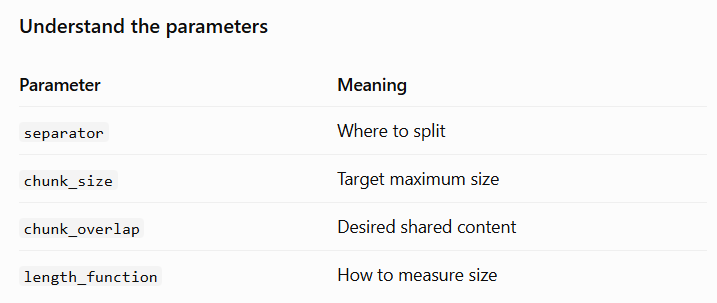

# Program 2: CharacterTextSplitter with a different separator

In [ ]:
from langchain_text_splitters import CharacterTextSplitter

text = """
Python is easy to learn.
Python supports OOP.
Machine learning uses data.
Deep learning uses neural networks.
"""

splitter = CharacterTextSplitter(
    separator=".",
    chunk_size=50,
    chunk_overlap=5,
    length_function=len
)

chunks = splitter.split_text(text)

for i, chunk in enumerate(chunks):

    print(f"Chunk {i+1}: {chunk}")

Chunk 1: Python is easy to learn.
Python supports OOP
Chunk 2: Machine learning uses data
Chunk 3: Deep learning uses neural networks.


# RecursiveCharacterTextSplitter

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text = """
Python is a high-level programming language.

Python supports object-oriented programming.

Machine learning is a subset of artificial intelligence.

Deep learning uses neural networks to learn complex patterns.

Natural language processing allows computers to understand human language.
"""

splitter = RecursiveCharacterTextSplitter(
    chunk_size=100,
    chunk_overlap=20
)

chunks = splitter.split_text(text)

for i, chunk in enumerate(chunks):

    print(f"\nChunk {i+1}")

    print(chunk)

    print("Length:", len(chunk))

    print("-" * 40)


Chunk 1
Python is a high-level programming language.

Python supports object-oriented programming.
Length: 90
----------------------------------------

Chunk 2
Machine learning is a subset of artificial intelligence.
Length: 56
----------------------------------------

Chunk 3
Deep learning uses neural networks to learn complex patterns.
Length: 61
----------------------------------------

Chunk 4
Natural language processing allows computers to understand human language.
Length: 74
----------------------------------------


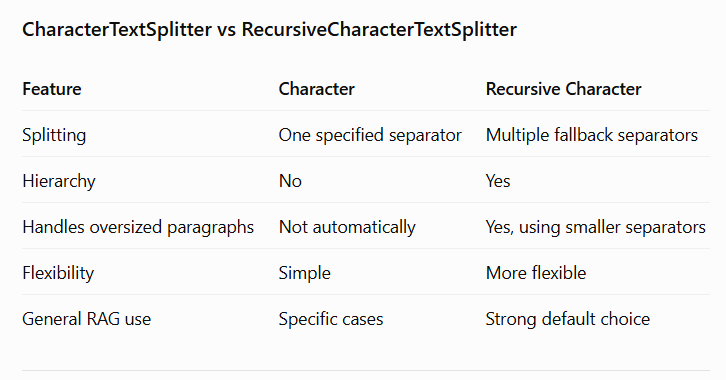

# Program 5: Split Documents and preserve metadata

In [ ]:
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter

documents = [

    Document(
        page_content="""
        Python is a programming language.

        Python supports object-oriented programming.

        Python supports multiple programming paradigms.
        """,
        metadata={
            "source": "python.pdf",
            "page": 1
        }
    ),

    Document(
        page_content="""
        Machine learning is a subset of AI.

        It uses algorithms to learn patterns from data.

        Deep learning uses neural networks.
        """,
        metadata={
            "source": "ml.pdf",
            "page": 2
        }
    )
]

splitter = RecursiveCharacterTextSplitter(
    chunk_size=100,
    chunk_overlap=20
)

chunks = splitter.split_documents(documents)

print("Total chunks:", len(chunks))

for i, chunk in enumerate(chunks):

    print(f"\nChunk {i+1}")

    print("Content:", chunk.page_content)

    print("Metadata:", chunk.metadata)

    print("-" * 50)

Total chunks: 5

Chunk 1
Content: Python is a programming language.

        Python supports object-oriented programming.
Metadata: {'source': 'python.pdf', 'page': 1}
--------------------------------------------------

Chunk 2
Content: Python supports multiple programming paradigms.
Metadata: {'source': 'python.pdf', 'page': 1}
--------------------------------------------------

Chunk 3
Content: Machine learning is a subset of AI.
Metadata: {'source': 'ml.pdf', 'page': 2}
--------------------------------------------------

Chunk 4
Content: It uses algorithms to learn patterns from data.
Metadata: {'source': 'ml.pdf', 'page': 2}
--------------------------------------------------

Chunk 5
Content: Deep learning uses neural networks.
Metadata: {'source': 'ml.pdf', 'page': 2}
--------------------------------------------------


#  MarkdownHeaderTextSplitter

# Python

Python is a programming language.

## Features

Python supports object-oriented programming.

## Applications

Python is used in AI and machine learning.

# Program 1

In [ ]:
from langchain_text_splitters import MarkdownHeaderTextSplitter

markdown_document = """
# Python

Python is a programming language.

## Features

Python supports object-oriented programming.

Python is dynamically typed.

## Applications

Python is used in AI and machine learning.

Python is used in data science.
"""

headers_to_split_on = [
    ("#","Header 1"),
    ("##","Header 2")
]
splitter=MarkdownHeaderTextSplitter(
    headers_to_split_on=headers_to_split_on
)


chunks = splitter.split_text(markdown_document)

for i, chunk in enumerate(chunks):

    print(f"\nChunk {i+1}")

    print("Content:", chunk.page_content)

    print("Metadata:", chunk.metadata)

    print("-" * 50)


Chunk 1
Content: Python is a programming language.
Metadata: {'Header 1': 'Python'}
--------------------------------------------------

Chunk 2
Content: Python supports object-oriented programming.  
Python is dynamically typed.
Metadata: {'Header 1': 'Python', 'Header 2': 'Features'}
--------------------------------------------------

Chunk 3
Content: Python is used in AI and machine learning.  
Python is used in data science.
Metadata: {'Header 1': 'Python', 'Header 2': 'Applications'}
--------------------------------------------------


# Program 2: Markdown splitting with three heading levels

In [ ]:
from langchain_text_splitters import MarkdownHeaderTextSplitter

markdown_text = """
# Machine Learning

Introduction to ML.

## Supervised Learning

Learning using labeled data.

### Classification

Predicting categories.

### Regression

Predicting continuous values.

## Unsupervised Learning

Learning from unlabeled data.
"""

headers = [
    ("#", "H1"),
    ("##", "H2"),
    ("###", "H3")
]
splitter=MarkdownHeaderTextSplitter(
    headers_to_split_on=headers
)
documents=splitter.split_text(markdown_text)

for doc in documents:
    print("Content:", doc.page_content)

    print("Metadata:", doc.metadata)

    print("-" * 40)

Content: Introduction to ML.
Metadata: {'H1': 'Machine Learning'}
----------------------------------------
Content: Learning using labeled data.
Metadata: {'H1': 'Machine Learning', 'H2': 'Supervised Learning'}
----------------------------------------
Content: Predicting categories.
Metadata: {'H1': 'Machine Learning', 'H2': 'Supervised Learning', 'H3': 'Classification'}
----------------------------------------
Content: Predicting continuous values.
Metadata: {'H1': 'Machine Learning', 'H2': 'Supervised Learning', 'H3': 'Regression'}
----------------------------------------
Content: Learning from unlabeled data.
Metadata: {'H1': 'Machine Learning', 'H2': 'Unsupervised Learning'}
----------------------------------------


# Program 3: Combine Markdown splitting and recursive splitting

In [ ]:
from langchain_text_splitters import (
    MarkdownHeaderTextSplitter,
    RecursiveCharacterTextSplitter
)

markdown_text = """
# Deep Learning

Deep learning is a subset of machine learning.

## Neural Networks

Neural networks consist of interconnected neurons.

They learn complex patterns from large datasets.

## CNN

CNNs are commonly used in image processing.

## RNN

RNNs are used for sequential data.
"""

headers = [
    ("#", "Topic"),
    ("##", "Subtopic")
]

header_splitter = MarkdownHeaderTextSplitter(
    headers_to_split_on=headers
)

header_chunks = header_splitter.split_text(markdown_text)

recursive_splitter = RecursiveCharacterTextSplitter(
    chunk_size=100,
    chunk_overlap=20
)

final_chunks = recursive_splitter.split_documents(
    header_chunks
)

for i, chunk in enumerate(final_chunks):

    print(f"\nChunk {i+1}")

    print(chunk.page_content)

    print(chunk.metadata)


Chunk 1
Deep learning is a subset of machine learning.
{'Topic': 'Deep Learning'}

Chunk 2
Neural networks consist of interconnected neurons.
{'Topic': 'Deep Learning', 'Subtopic': 'Neural Networks'}

Chunk 3
They learn complex patterns from large datasets.
{'Topic': 'Deep Learning', 'Subtopic': 'Neural Networks'}

Chunk 4
CNNs are commonly used in image processing.
{'Topic': 'Deep Learning', 'Subtopic': 'CNN'}

Chunk 5
RNNs are used for sequential data.
{'Topic': 'Deep Learning', 'Subtopic': 'RNN'}


# Sentence-based splitting

In [ ]:
import nltk

nltk.download("punkt_tab")

from nltk.tokenize import sent_tokenize

text = """
Python is a programming language.
It is easy to learn.
Machine learning uses algorithms.
Deep learning uses neural networks.
"""

sentences = sent_tokenize(text)

for i, sentence in enumerate(sentences):

    print(f"Sentence {i+1}: {sentence}")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Sentence 1: 
Python is a programming language.
Sentence 2: It is easy to learn.
Sentence 3: Machine learning uses algorithms.
Sentence 4: Deep learning uses neural networks.


In [ ]:
from nltk.tokenize import sent_tokenize

text = """
Python is a programming language.
It is easy to learn.
Machine learning uses algorithms.
Deep learning uses neural networks.
Natural language processing works with human language.
"""

sentences = sent_tokenize(text)

chunk_size = 2

chunks = []

for i in range(0, len(sentences), chunk_size):

    chunk = " ".join(
        sentences[i:i + chunk_size]
    )

    chunks.append(chunk)

for i, chunk in enumerate(chunks):

    print(f"Chunk {i+1}: {chunk}")

Chunk 1: 
Python is a programming language. It is easy to learn.
Chunk 2: Machine learning uses algorithms. Deep learning uses neural networks.
Chunk 3: Natural language processing works with human language.


In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter, Language

code = """
def add(a, b):
    return a + b

def subtract(a, b):
    return a - b

class Calculator:

    def multiply(self, a, b):
        return a * b
"""

splitter = RecursiveCharacterTextSplitter.from_language(
    language=Language.PYTHON,
    chunk_size=100,
    chunk_overlap=10
)

chunks = splitter.split_text(code)

for i, chunk in enumerate(chunks):

    print(f"\nChunk {i+1}")

    print(chunk)

    print("-" * 40)


Chunk 1
def add(a, b):
    return a + b

def subtract(a, b):
    return a - b
----------------------------------------

Chunk 2
class Calculator:

    def multiply(self, a, b):
        return a * b
----------------------------------------


#  Chunking different document formats

# Program 1: Chunk PDF documents

In [ ]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Step 1: Load PDF
loader = PyPDFLoader("DBMS.pdf")

documents = loader.load()

# Step 2: Create splitter
splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=150
)

# Step 3: Split documents
chunks = splitter.split_documents(documents)

# Step 4: Display chunks
print("Original pages:", len(documents))

print("Total chunks:", len(chunks))

for i, chunk in enumerate(chunks):

    print(f"\nChunk {i+1}")

    print("Content:", chunk.page_content[:300])

    print("Metadata:", chunk.metadata)

    print("-" * 50)

# Program 2: Chunk multiple PDF documents

In [ ]:
import os

from langchain_community.document_loaders import PyPDFLoader

from langchain_text_splitters import RecursiveCharacterTextSplitter

folder_path = "pdfs"

all_documents = []

# Load PDFs
for filename in os.listdir(folder_path):

    if filename.lower().endswith(".pdf"):

        path = os.path.join(folder_path, filename)

        loader = PyPDFLoader(path)

        documents = loader.load()

        all_documents.extend(documents)


# Split documents
splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=150
)

chunks = splitter.split_documents(all_documents)

print("Total pages:", len(all_documents))

print("Total chunks:", len(chunks))

# Program 3: Chunk Word documents

In [ ]:
from langchain_community.document_loaders import Docx2txtLoader

from langchain_text_splitters import RecursiveCharacterTextSplitter

loader = Docx2txtLoader("ML_Notes.docx")

documents = loader.load()

splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50
)

chunks = splitter.split_documents(documents)

for i, chunk in enumerate(chunks):

    print(f"\nChunk {i+1}")

    print(chunk.page_content)

    print(chunk.metadata)

# Program 4: Chunk CSV documents

In [ ]:
import pandas as pd

from langchain_core.documents import Document

from langchain_text_splitters import RecursiveCharacterTextSplitter

df = pd.read_csv("students.csv")

documents = []

# Convert each row into a document
for index, row in df.iterrows():

    content = "\n".join(
        f"{column}: {value}"
        for column, value in row.items()
    )

    documents.append(
        Document(
            page_content=content,
            metadata={
                "source": "students.csv",
                "row": index
            }
        )
    )


# Split documents if necessary
splitter = RecursiveCharacterTextSplitter(
    chunk_size=300,
    chunk_overlap=30
)

chunks = splitter.split_documents(documents)

for i, chunk in enumerate(chunks):

    print(f"\nChunk {i+1}")

    print(chunk.page_content)

    print(chunk.metadata)

# Program 5: Chunk Excel documents

In [ ]:
import pandas as pd

from langchain_core.documents import Document

from langchain_text_splitters import RecursiveCharacterTextSplitter

df = pd.read_excel("employees.xlsx")

documents = []

for index, row in df.iterrows():

    content = "\n".join(
        f"{column}: {value}"
        for column, value in row.items()
    )

    documents.append(
        Document(
            page_content=content,
            metadata={
                "source": "employees.xlsx",
                "row": index
            }
        )
    )

splitter = RecursiveCharacterTextSplitter(
    chunk_size=300,
    chunk_overlap=30
)

chunks = splitter.split_documents(documents)

print("Total Excel rows:", len(documents))

print("Total chunks:", len(chunks))